# Capacity Allocator

Charts of the model's results, each drawn from the published CSVs by the chart functions the model uses. Run the first cell, then any cell on its own.

**All data is synthetic**, drawn from distributions fitted to real retrospective output.

Setup:

```
python run_demo.py                                                    # moves/review/detail
cd ../generator && python run_fitted.py --cases --out ../output && python run_fitted.py --verified 25 --out ../output
cd ../generator && python fit_diagnostics.py --out ../output
```

Run the next cell, then any cell on its own.

In [27]:
%matplotlib inline
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

HERE = None
for base in [Path.cwd(), *Path.cwd().parents]:
    for candidate in (base, base / "model"):
        if (candidate / "capacity_allocator").is_dir():
            HERE = candidate
            sys.path.insert(0, str(HERE))
            break
    if HERE is not None:
        break
if HERE is None:
    raise FileNotFoundError("could not find model/capacity_allocator from the current working directory")

PROJECT = HERE.parent if HERE.name == "model" else HERE
OUTPUT = PROJECT / "output"
DATA = OUTPUT / "data"

from capacity_allocator import charts, config as cfg, run as outputs, scenarios

REQUIRED = ["moves", "review", "detail", "fitted_days", "fitted_cooccurrence",
            "fitted_families_per_day", "fitted_cases"]
missing = [n for n in REQUIRED
           if not (DATA / f"{n}.csv").exists() or not (DATA / f"{n}.csv").stat().st_size]
assert not missing, f"missing {missing} in {DATA} - see the setup commands above"

moves = pd.read_csv(DATA / "moves.csv")
review = pd.read_csv(DATA / "review.csv")
detail = pd.read_csv(DATA / "detail.csv")
fitted_days = pd.read_csv(DATA / "fitted_days.csv")
fitted_pairs = pd.read_csv(DATA / "fitted_cooccurrence.csv")
fitted_spread = pd.read_csv(DATA / "fitted_families_per_day.csv")


def _maybe(name):
    p = DATA / f"{name}.csv"
    return pd.read_csv(p) if p.exists() and p.stat().st_size else None

def det(name):
    return detail[detail["scenario"] == name]

def rev(name): 
    return review[review["scenario"] == name]

def breaches(scenario):
    """Operational ranks with a non-zero value either side, worst first. Slacks only -
    a guardrail value is risk carried, not a defect."""
    r = rev(scenario).query("kind == 'slack'")
    r = r[(r["slack_actual"] > outputs.EPS) | (r["slack_optimal"] > outputs.EPS)]
    return r.sort_values("slack_actual", ascending=False)[
        ["priority", "tier", "label", "slack_actual", "slack_optimal", "outcome"]]
        
def risk_carried(scenario):
    g = rev(scenario).query("kind == 'guardrail'")[["slack_actual", "slack_optimal"]].sum()
    return g.rename({"slack_actual": "before", "slack_optimal": "after"})

ORDER = [s for s in scenarios.ORDER if s in set(review["scenario"])]
FITTED = sorted(s for s in set(review["scenario"]) if s.startswith("fitted_"))
N_TIERS = review.groupby("scenario").size().iloc[0]
N_HOURS = detail.groupby("scenario").size().iloc[0]

def case(seed): return f"fitted_{seed}"

def det(name): return detail[detail["scenario"] == name].reset_index(drop=True)
def headline(name): return scenarios.get(name).headline

limit_mix = _maybe("fitted_limit_mix")
CASES = pd.read_csv(DATA / "fitted_cases.csv").set_index("seed").to_dict("index")






# Figure export writes the report's PDFs under their exact filenames. Off by default so a
# casual run cannot overwrite what the current build is using.
SAVE_FIGURES = os.environ.get("SAVE_FIGURES", "0") == "1"
FIGDIR = Path(os.environ.get("FIGDIR", OUTPUT / "figures"))


def save(fig, stem):
    """Save as PDF with chart titles blanked - the report is built with pdflatex, and its
    captions carry the takeaway while the on-screen titles say which scenario this is."""
    if not SAVE_FIGURES:
        return
    sup = getattr(fig, "_suptitle", None)
    sup_text = sup.get_text() if sup is not None else None
    held = [[(loc, ax.get_title(loc)) for loc in ("left", "center", "right")]
            for ax in fig.axes]
    for ax, titles in zip(fig.axes, held):
        for loc, _ in titles:
            ax.set_title("", loc=loc)
    if sup_text:
        fig.suptitle("")
    FIGDIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGDIR / f"{stem}.pdf", bbox_inches="tight")
    for ax, titles in zip(fig.axes, held):
        for loc, text in titles:
            ax.set_title(text, loc=loc)
    if sup_text:
        fig.suptitle(sup_text)
    print(f"wrote {stem}.pdf")




# The trio sharing one identical breach, derived so it cannot go stale if a scenario is retuned.
PEAK = (review.query("kind == 'slack' and scenario in @ORDER")
        .loc[lambda d: d.groupby("scenario")["slack_actual"].idxmax()]
        .set_index("scenario")["slack_actual"].round())
SHARED = PEAK[PEAK > 0].value_counts().idxmax()
TRIO = [s for s in ORDER if PEAK.get(s) == SHARED]
DAY = 90065

plt.rcParams["figure.dpi"] = 110
FIGSIZE = charts.SIZE_SERIES

print(f"{len(ORDER)} engineered + {len(FITTED)} fitted days | {N_TIERS} ranks | "
      f"{N_HOURS}h horizon | export {'ON' if SAVE_FIGURES else 'off'}")
review.query("priority == 1").set_index("scenario").loc[
    ORDER, ["moves_total", "limited_by", "resolved"]]

8 engineered + 3 fitted days | 15 ranks | 24h horizon | export off


,moves_total,limited_by,resolved
scenario,,,
baseline,25,resolved,True
ib_surge,53,resolved,True
ob_backlog_build,32,resolved,True
cpt_at_risk,35,resolved,True
eod_target_miss,53,resolved,True
ib_then_eod,83,resolved,True
machine_capped,4,machine,False
pool_exhausted,12,cross_trained_people,False


---
## Method

Six work blocks in 24 hours. Moves happen at block boundaries only.

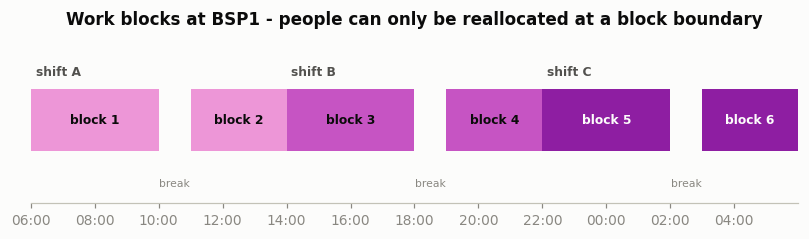

In [28]:
fig, ax = plt.subplots(figsize=charts.SIZE_TIMELINE)
charts.shift_timeline(ax)

The fifteen ranks, read off `review.csv`
Ranks 1-11 are defects, 12-13 risk carried, 14-15 price.

In [29]:
rev(ORDER[0])[["priority", "tier", "label", "kind"]].set_index("priority").rename_axis("rank")

,tier,label,kind
rank,,,
1,storage_now,Inbound storage (this shift),slack
2,storage_later,Inbound storage (later),slack
3,cpt_now,Carrier cut-off risk (this shift),slack
4,cpt_later,Carrier cut-off risk (later),slack
5,ob_bl_max_now,Outbound backlog too high (this shift),slack
6,ob_bl_max_later,Outbound backlog too high (later),slack
7,eod_max,End-of-day backlog above target,slack
8,ob_bl_min_now,Outbound backlog too low (this shift),slack
9,ob_bl_min_later,Outbound backlog too low (later),slack


---
## Results

Each scenario is a pair: **forecast** is the planned roster with nobody moving, **optimised**
is the recommendation. Every before/after chart is the difference.

### 1. Nothing is broken, and the allocation is still not the best one

No limit broken anywhere, 25 people still recommended. The dashed line is the band centre -
that is what the model is aiming at.

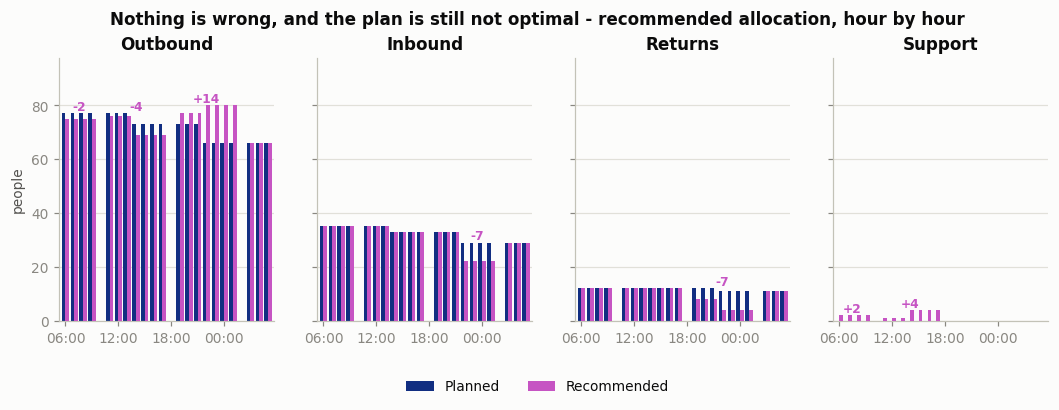

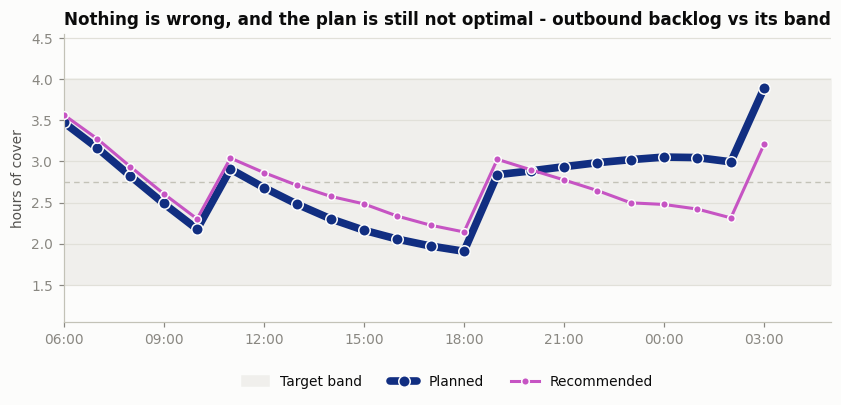

In [30]:
fig, axes = plt.subplots(1, len(charts.HEADCOUNT_DEPTS),
                         figsize=charts.size_headcount(), sharey=True)
charts.headcount(det("baseline"), axes, headline("baseline"))

fig, ax = plt.subplots(figsize=FIGSIZE)
charts.ob_backlog(det("baseline"), ax, headline("baseline"))


In [31]:
g = risk_carried("baseline")
print(f"operational ranks non-zero : {len(breaches('baseline'))}")
print(f"risk carried               : {g['before']:,.0f} -> {g['after']:,.0f} units"
      f"  ({1 - g['after'] / g['before']:.0%} reduction)")
print(f"movements                  : {rev('baseline')['moves_total'].iloc[0]}")

operational ranks non-zero : 0
risk carried               : 15,115 -> 1,806 units  (88% reduction)
movements                  : 25


### 2. Inbound floods the building

Arrivals double for six hours. Storage ranks first, so this is the model spending one
department to protect another.

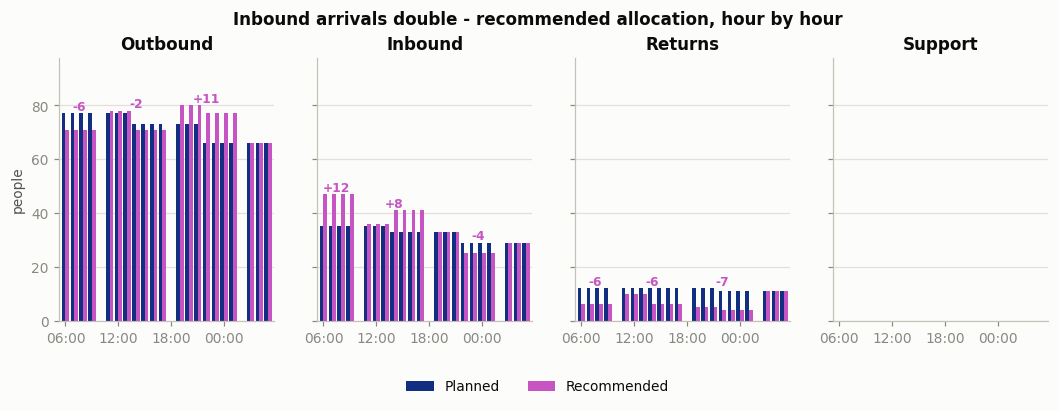

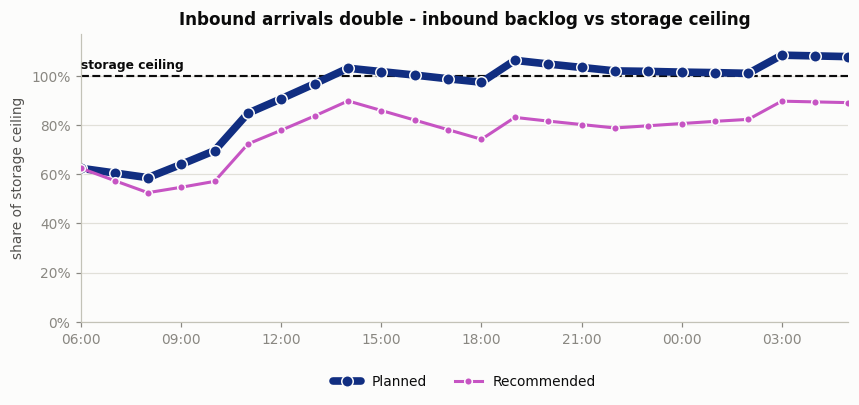

In [32]:
fig, axes = plt.subplots(1, len(charts.HEADCOUNT_DEPTS),
                         figsize=charts.size_headcount(), sharey=True)
charts.headcount(det("ib_surge"), axes, headline("ib_surge"))

fig, ax = plt.subplots(figsize=FIGSIZE)
charts.ib_storage(det("ib_surge"), ax, headline("ib_surge"))


In [33]:
x = det("ib_surge")
print(f"hours over the ceiling, planned : {int((x['ib_storage_actual_pct'] > 1).sum())} of {len(x)}")
print(f"peak planned / recommended      : {x['ib_storage_actual_pct'].max():.1%}"
      f" / {x['ib_storage_optimal_pct'].max():.1%}")
display(breaches("ib_surge"))

# Outbound funds Inbound, then Returns backfills Outbound - the tightest constraint paid for
# out of the loosest.
display(moves.query("scenario == 'ib_surge'")[["quarter", "hour", "from", "to", "people"]])

hours over the ceiling, planned : 14 of 24
peak planned / recommended      : 108.4% / 89.8%


,priority,tier,label,slack_actual,slack_optimal,outcome
16,2,storage_later,Inbound storage (later),14415.3,0.0,resolved


,quarter,hour,from,to,people
6,1,06:00,Outbound,Inbound,12
7,1,06:00,Returns,Outbound,6
8,2,11:00,Outbound,Inbound,1
9,2,11:00,Returns,Outbound,2
10,3,14:00,Outbound,Inbound,8
11,3,14:00,Returns,Outbound,6
12,4,19:00,Returns,Outbound,7
13,5,22:00,Inbound,Outbound,4
14,5,22:00,Returns,Outbound,7


### 3. A carrier leaves short

Risk is cumulative demand against cumulative capacity to each deadline, against a 95%
tolerance. Above 100% is a truck leaving short.

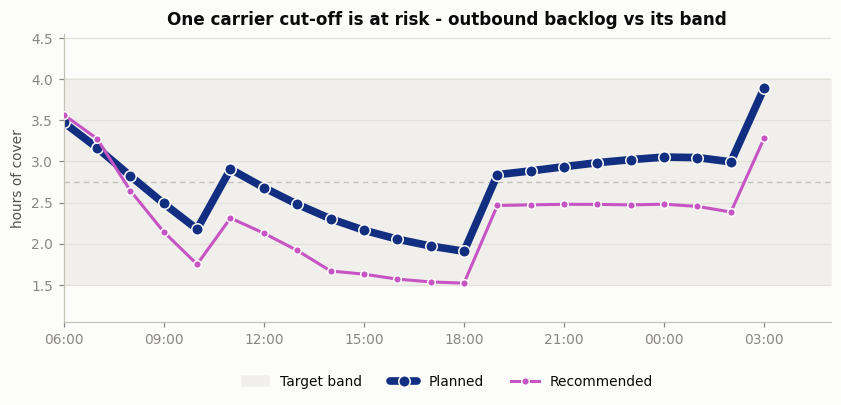

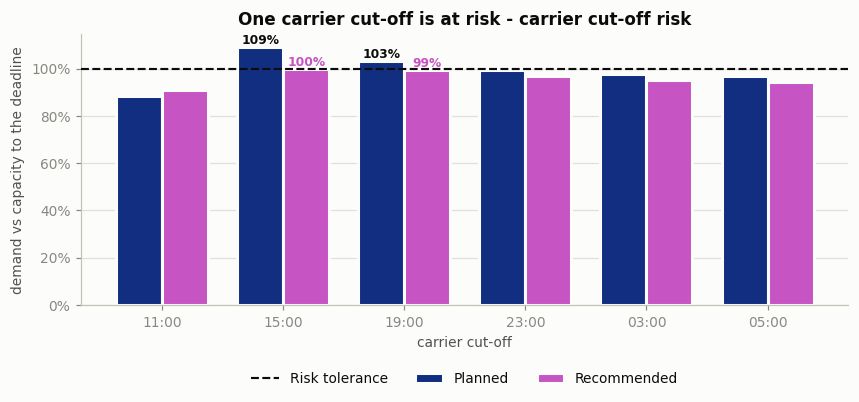

In [34]:
fig, ax = plt.subplots(figsize=FIGSIZE)
charts.ob_backlog(det("cpt_at_risk"), ax, headline("cpt_at_risk"))

fig, ax = plt.subplots(figsize=charts.SIZE_CPT)
charts.cpt_risk(det("cpt_at_risk"), ax, headline("cpt_at_risk"))


In [35]:
c = (det("cpt_at_risk").dropna(subset=["cpt_index"])
     [["cpt_clock", "cpt_risk_actual_pct", "cpt_risk_optimal_pct"]]
     .rename(columns={"cpt_clock": "departs", "cpt_risk_actual_pct": "planned",
                      "cpt_risk_optimal_pct": "recommended"}))
print(c.to_string(index=False, formatters={"planned": "{:.1%}".format,
                                           "recommended": "{:.1%}".format}))
print(f"\nmovements: {rev('cpt_at_risk')['moves_total'].iloc[0]}")
print("11:00 gets worse because it had slack and the model spent it - the trade is stated,"
      " not hidden.")

departs planned recommended
  11:00   88.4%       90.8%
  15:00  109.2%      100.0%
  19:00  103.3%       99.4%
  23:00   99.3%       96.7%
  03:00   97.7%       95.1%
  05:00   96.9%       94.5%

movements: 35
11:00 gets worse because it had slack and the model spent it - the trade is stated, not hidden.


### 4. The same breach, three answers

The central result: identical breach, three different walls, three different owners.

In [36]:
print(f"{SHARED:,.0f} units breached identically in: {', '.join(TRIO)}\n")
for s in TRIO:
    b = breaches(s).iloc[0]
    print(f"{s:<18} {int(rev(s)['moves_total'].iloc[0]):>3} moves   "
          f"{1 - b['slack_optimal'] / b['slack_actual']:>5.0%} recovered   "
          f"limited_by = {rev(s)['limited_by'].iloc[0]}")

22,662 units breached identically in: ob_backlog_build, machine_capped, pool_exhausted

ob_backlog_build    32 moves    100% recovered   limited_by = resolved
machine_capped       4 moves     44% recovered   limited_by = machine
pool_exhausted      12 moves     83% recovered   limited_by = cross_trained_people


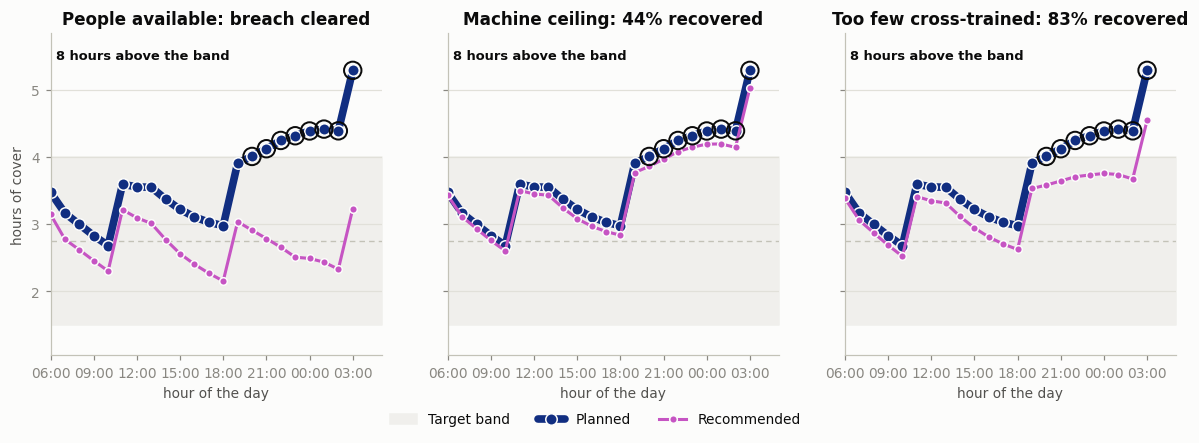

In [37]:
PANEL = {"ob_backlog_build": "People available: breach cleared",
         "machine_capped":   "Machine ceiling: 44% recovered",
         "pool_exhausted":   "Too few cross-trained: 83% recovered"}

fig, axes = plt.subplots(1, len(TRIO), figsize=(4.4 * len(TRIO), 3.8), sharey=True)
for ax, name in zip(axes, TRIO):
    charts.ob_backlog(det(name), ax, title=PANEL.get(name, name))
    ax.set_xlabel("hour of the day")
    if ax.get_legend():
        ax.get_legend().remove()
axes[0].set_ylabel("hours of cover")
for ax in axes[1:]:
    ax.set_ylabel("")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.09))


In [38]:
# The ceiling is visible in the recommendation itself, not only in the label.
for s in TRIO:
    x = det(s)
    d = (x["ob_capacity_optimal_units"] - x["ob_capacity_actual_units"]).abs()
    print(f"{s:<18} largest single-hour capacity change: {d.max():>8,.0f} units")

wall = det("machine_capped").query("ob_capacity_limited_by == 'machine'")
print(f"\nmachine_capped pinned at the ceiling for {len(wall)} hours: {', '.join(wall['clock'])}")

ob_backlog_build   largest single-hour capacity change:    1,662 units
machine_capped     largest single-hour capacity change:      126 units
pool_exhausted     largest single-hour capacity change:      252 units

machine_capped pinned at the ceiling for 6 hours: 20:00, 21:00, 22:00, 23:00, 00:00, 01:00


### 5. Two limits, pulling opposite ways

Inbound storage breaks in the morning, the end-of-day target at 23:00, and they want the
same people in different departments.

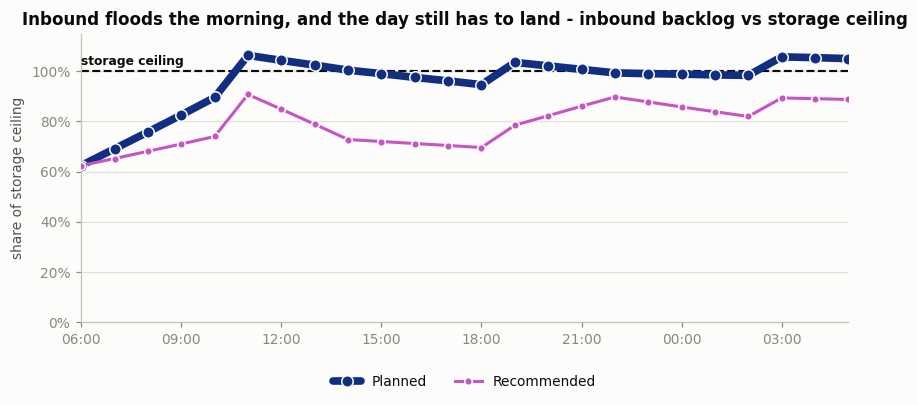

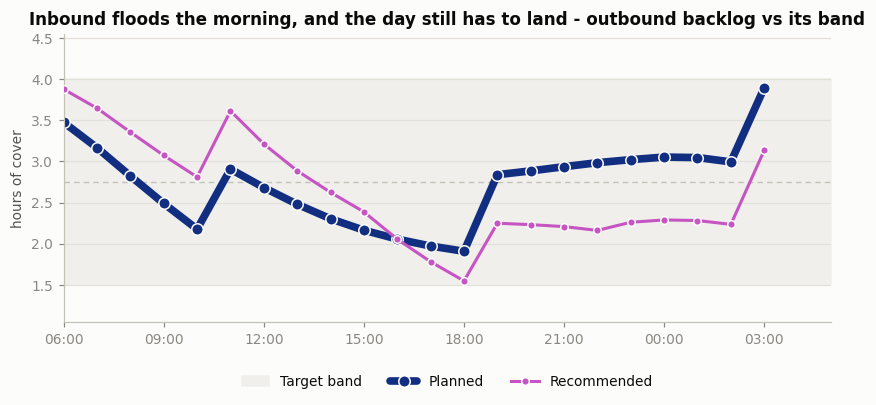

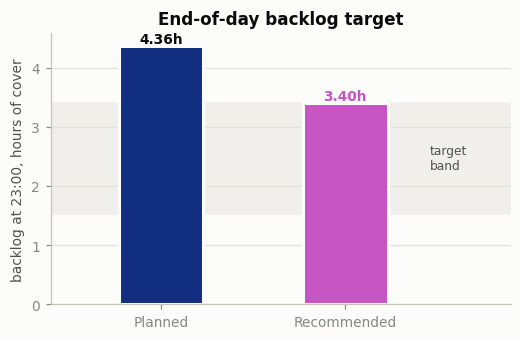

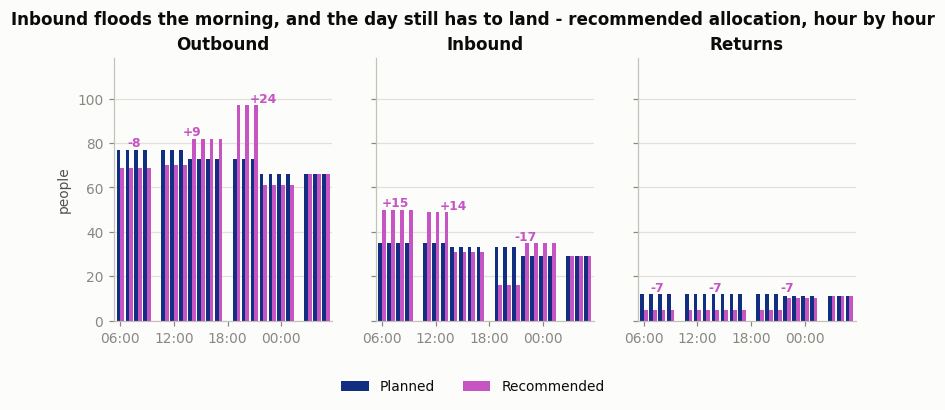

In [39]:
S = "ib_then_eod"

fig, ax = plt.subplots(figsize=FIGSIZE)
charts.ib_storage(det(S), ax, headline(S))

fig, ax = plt.subplots(figsize=FIGSIZE)
charts.ob_backlog(det(S), ax, headline(S))

fig, ax = plt.subplots(figsize=charts.SIZE_EOD)
charts.eod_backlog(det(S), ax, headline(S))

# Support dropped: it is the sink for spare people and has no planned headcount.
SHOWN = [d for d in charts.HEADCOUNT_DEPTS if d != cfg.SP]
fig, axes = plt.subplots(1, len(SHOWN), figsize=charts.size_headcount(SHOWN), sharey=True)
charts.headcount(det(S), axes, headline(S), depts=SHOWN)


In [40]:
x = det(S)
e = x[x["hour"] == cfg.EOD_HOUR].iloc[0]
den = e["eod_capacity_per_hour"]
print(f"storage peak  {x['ib_storage_actual_pct'].max():.1%} -> "
      f"{x['ib_storage_optimal_pct'].max():.1%}")
print(f"end of day    {e['ob_total_actual_units'] / den:.2f}h -> "
      f"{e['ob_total_optimal_units'] / den:.2f}h  (target {e['eod_soft_max_hours']:.2f}h)")
print(f"movements     {rev(S)['moves_total'].iloc[0]}\n")
display(breaches(S))

# The flow reverses at midday: the same associate is in a different department at 08:00 and 16:00.
display(moves.query("scenario == @S").pivot_table(
    index="hour", columns="to", values="people", aggfunc="sum").fillna(0).astype(int))

storage peak  106.4% -> 90.8%
end of day    4.36h -> 3.40h  (target 3.40h)
movements     83



,priority,tier,label,slack_actual,slack_optimal,outcome
81,7,eod_max,End-of-day backlog above target,6925.9,0.0,resolved
76,2,storage_later,Inbound storage (later),6587.3,0.0,resolved
75,1,storage_now,Inbound storage (this shift),3724.0,0.0,resolved


to,Inbound,Outbound
hour,,
06:00,15,7
11:00,14,7
14:00,0,9
19:00,0,24
22:00,6,1


### 6. Days nobody engineered

Engineered days break one limit. Real-shaped days break two to four.

<BarContainer object of 4 artists>

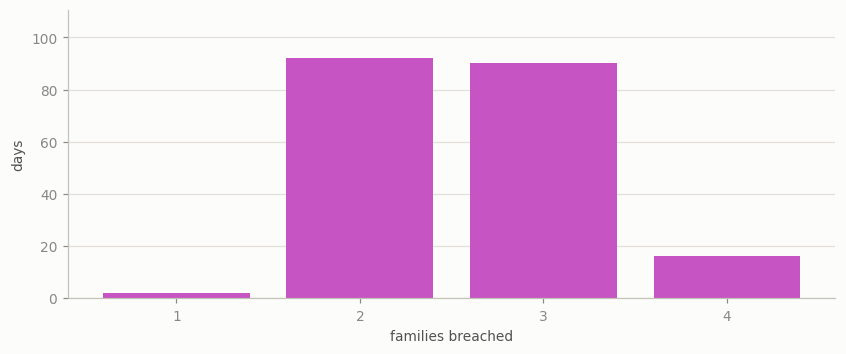

In [41]:
fig, ax = plt.subplots(figsize=charts.SIZE_FAMILIES)
charts.families_per_day(fitted_spread, ax, title="")

In [42]:
n = int(fitted_spread["days_scanned"].iloc[0])
one = fitted_spread.query("families_breached == 1")
print(one)
print(f"{int(one['days'].iloc[0])} of {n} days break a single family "
      f"({one['share'].iloc[0]:.0%}) - where every engineered scenario sits.\n")

# Which families keep each other company. cpt is live on every day; ob_bl_max is a strict
# subset of it, so a tight deadline and a full building always arrive together.
live = {}
for r in fitted_pairs.itertuples():
    live[r.family_a], live[r.family_b] = r.days_a, r.days_b
for k, v in sorted(live.items(), key=lambda kv: -kv[1]):
    print(f"  {k:12s} live on {v:3d} of {n}")
print("\ninbound storage: absent - 0 of 200, and two engineered scenarios were built on it.")

   families_breached  days  share  days_scanned
0                  1     2   0.01           200
2 of 200 days break a single family (1%) - where every engineered scenario sits.

  cpt          live on 200 of 200
  ob_bl_max    live on 165 of 200
  eod_min      live on  57 of 200
  ob_bl_min    live on  51 of 200
  eod_max      live on  41 of 200
  returns_bl   live on   6 of 200

inbound storage: absent - 0 of 200, and two engineered scenarios were built on it.


#### Seed 90065 in full

Nothing special about it - no limit injected, no outcome chosen.

In [43]:
x = det(case(DAY))
arrivals, planned = x["ob_arrivals_units"].sum(), x["ob_capacity_actual_units"].sum()
print(CASES[DAY]["title"])
print(f"\noutbound receives {arrivals:,.0f} units against {planned:,.0f} of planned "
      f"capacity - {arrivals / planned - 1:.0%} more work than the roster can clear.")

Fine early, wrong by the end of the day

outbound receives 285,722 units against 236,018 of planned capacity - 21% more work than the roster can clear.


Text(0.5, 0.98, 'An unengineered day - seed 90065')

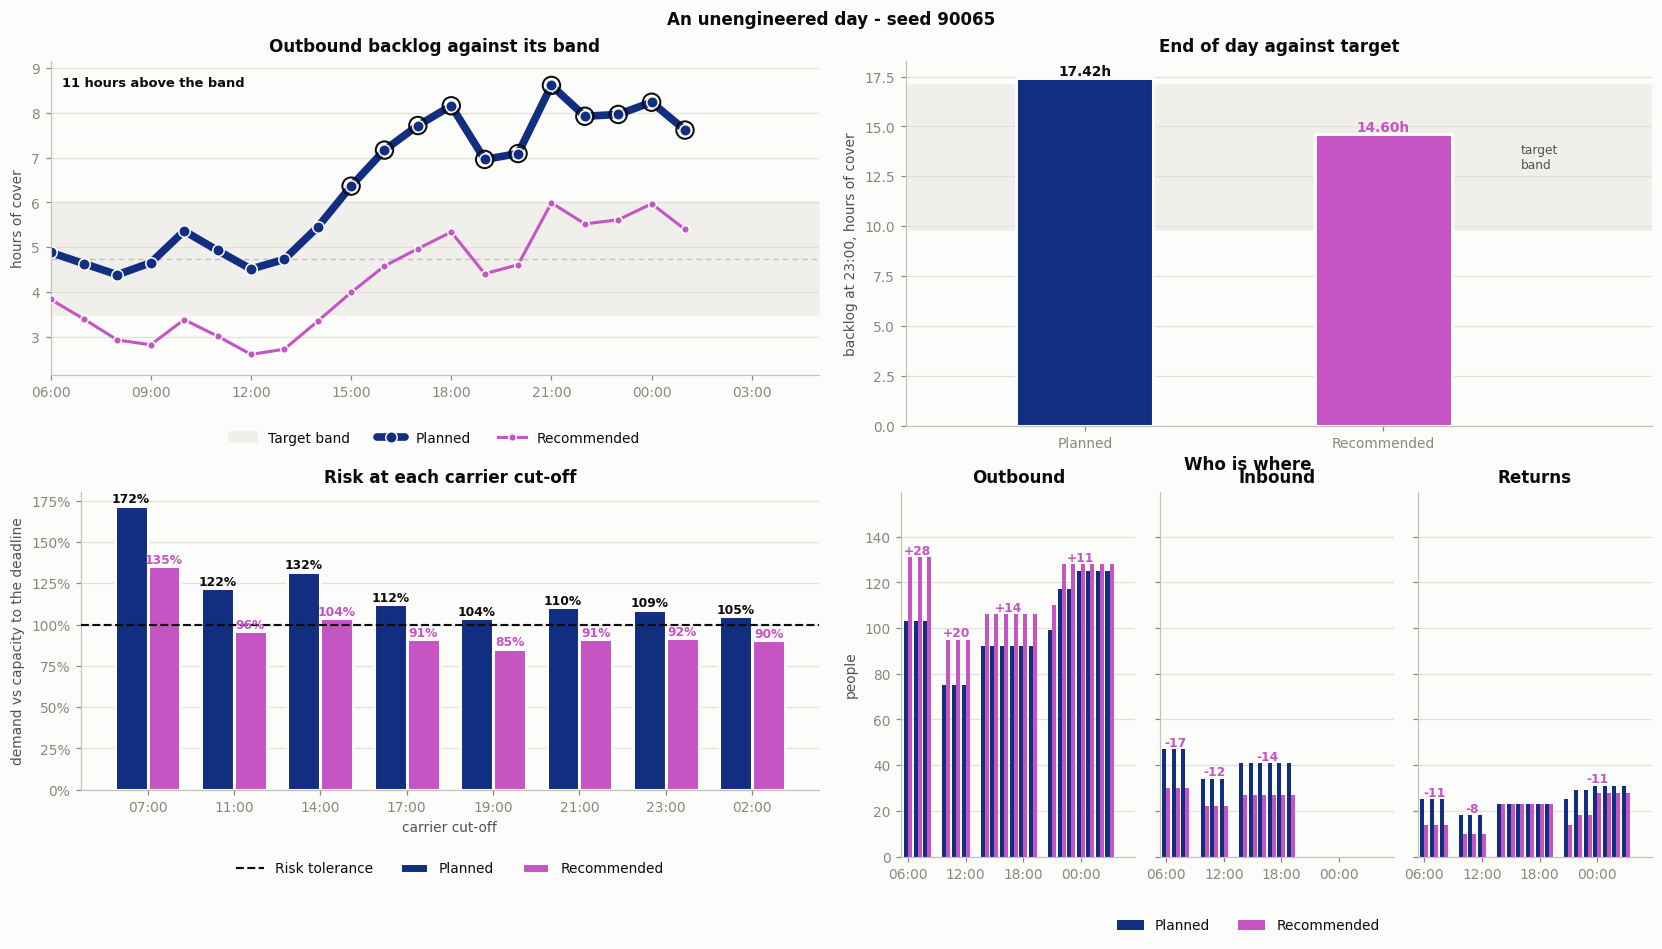

In [44]:
SHOWN = [d for d in charts.HEADCOUNT_DEPTS if d != cfg.SP]
d = det(case(DAY))

fig = plt.figure(figsize=(15.0, 8.0), layout="constrained")
sf = fig.subfigures(2, 2)
charts.ob_backlog(d, sf[0, 0].subplots(), title="Outbound backlog against its band")
charts.eod_backlog(d, sf[0, 1].subplots(), title="End of day against target")
charts.cpt_risk(d, sf[1, 0].subplots(), title="Risk at each carrier cut-off")
charts.headcount(d, sf[1, 1].subplots(1, len(SHOWN), sharey=True),
                 title="Who is where", depts=SHOWN)
fig.suptitle(f"An unengineered day - seed {DAY}", fontsize=11, fontweight="semibold")


In [45]:
c = x.dropna(subset=["cpt_index"])
print(f"trucks short: {int((c['cpt_risk_actual_pct'] > 1).sum())} of {len(c)} planned, "
      f"worst {c['cpt_risk_actual_pct'].max():.0%}  ->  "
      f"{int((c['cpt_risk_optimal_pct'] > 1).sum())} after")

below = x[x["ob_bl_optimal_hours"] < x["ob_bl_min_hours"]]
print(f"hours run below the band floor: {len(below)} "
      f"({below['clock'].iloc[0]}-{below['clock'].iloc[-1]})\n")
display(breaches(case(DAY)))

trucks short: 8 of 8 planned, worst 172%  ->  2 after
hours run below the band floor: 8 (07:00-14:00)



,priority,tier,label,slack_actual,slack_optimal,outcome
140,6,ob_bl_max_later,Outbound backlog too high (later),241225.2,0.0,resolved
138,4,cpt_later,Carrier cut-off risk (later),72580.9,3136.5,reduced
137,3,cpt_now,Carrier cut-off risk (this shift),18525.9,5516.2,reduced
141,7,eod_max,End-of-day backlog above target,3641.3,0.0,resolved
142,8,ob_bl_min_now,Outbound backlog too low (this shift),0.0,35290.8,broken to relieve a higher tier
143,9,ob_bl_min_later,Outbound backlog too low (later),0.0,11744.4,broken to relieve a higher tier


The floor is the cheapest rank to spend - on a day carrying 21% more work than capacity
nobody runs out of work - so the model spends it to pay for the cut-offs and the ceiling.
See the `outcome` column: `broken to relieve a higher tier`.

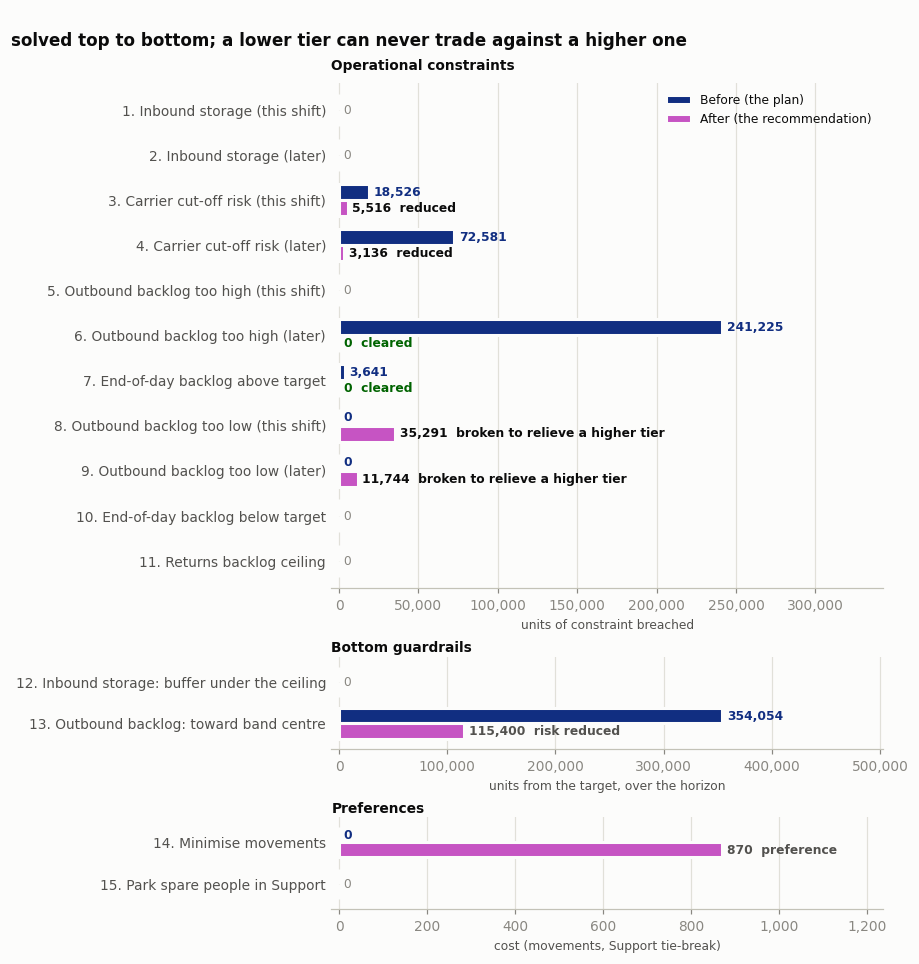

In [46]:
rungs = rev(case(DAY)).reset_index(drop=True)
fig, axes = plt.subplots(len(charts.ladder_ratios(rungs)), 1,
                         figsize=charts.size_ladder(rungs),
                         height_ratios=charts.ladder_ratios(rungs), layout="constrained")
charts.objective_ladder(rungs, axes, title="")


In [47]:
e = x[x["hour"] == cfg.EOD_HOUR].iloc[0]
den = e["eod_capacity_per_hour"]
last = x.dropna(subset=["ob_bl_optimal_hours"]).iloc[-1]
print(f"backlog finishes {last['ob_bl_optimal_hours']:.2f}h against a "
      f"{last['ob_bl_max_hours']:.2f}h ceiling")
print(f"end of day       {e['ob_total_actual_units'] / den:.2f}h -> "
      f"{e['ob_total_optimal_units'] / den:.2f}h against {e['eod_soft_max_hours']:.2f}h")
print(f"capacity added   {x['ob_capacity_optimal_units'].sum() / planned - 1:+.0%}")
print(f"cost             {rev(case(DAY))['moves_total'].iloc[0]} movements")

backlog finishes 5.40h against a 6.00h ceiling
end of day       17.42h -> 14.60h against 17.09h
capacity added   +14%
cost             87 movements


---
## Findings, limitations, next steps

The charts above show that the mechanism works on generated days. They do not show what would happen on a real operation.

---
## For the curious



### Two scenarios not shown above

`ob_backlog_build` is the mirror of the inbound surge - watch storage rise toward its
ceiling and stop under it. `eod_target_miss` is one scalar bound at 23:00 reshaping the
whole day.

inbound storage peaks at 79.2% and stays under.


,priority,tier,label,slack_actual,slack_optimal,outcome
66,7,eod_max,End-of-day backlog above target,6297.7,0.0,resolved


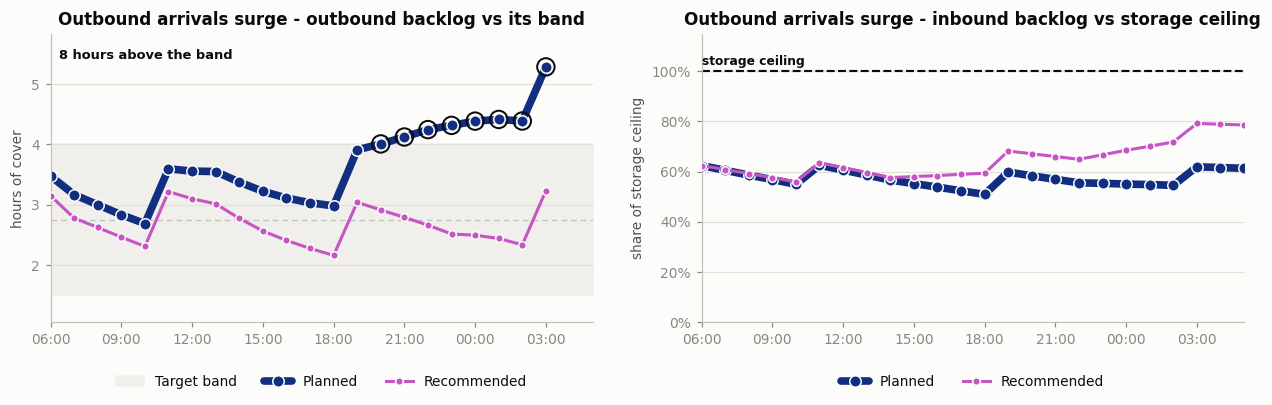

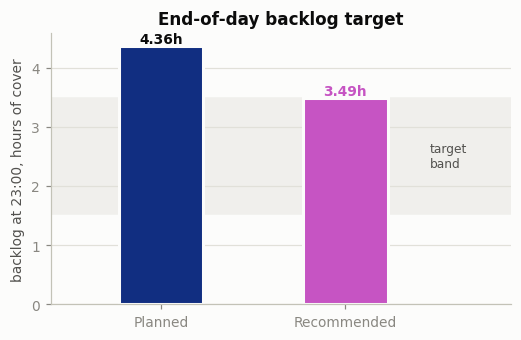

In [48]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14.0, 3.4))
charts.ob_backlog(det("ob_backlog_build"), left, headline("ob_backlog_build"))
charts.ib_storage(det("ob_backlog_build"), right, headline("ob_backlog_build"))
print(f"inbound storage peaks at "
      f"{det('ob_backlog_build')['ib_storage_optimal_pct'].max():.1%} and stays under.")

fig, ax = plt.subplots(figsize=charts.SIZE_EOD)
charts.eod_backlog(det("eod_target_miss"), ax, headline("eod_target_miss"))
display(breaches("eod_target_miss"))

### The 25-day sweep

Every pinned day was chosen by querying this, not by tuning.

In [49]:
f = fitted_days
uplift = f["ob_capacity_optimal"] / f["ob_capacity_actual"] - 1
print(f"{len(f)} days   |   no movement on {int((f['moves'] == 0).sum())} of them")
print(f"movements      mean {f['moves'].mean():.0f}, median {f['moves'].median():.0f}, "
      f"max {f['moves'].max():.0f}")
print(f"ranks breached mean {f['tiers_breached'].mean():.2f}, "
      f"cleared {f['tiers_resolved'].sum() / f['tiers_breached'].sum():.0%} of them")
print(f"capacity added mean {uplift.mean():+.1%}, p10 {uplift.quantile(0.1):+.1%}, "
      f"p90 {uplift.quantile(0.9):+.1%}\n")
display(f["limit"].value_counts().to_frame("days"))

25 days   |   no movement on 0 of them
movements      mean 101, median 102, max 199
ranks breached mean 4.40, cleared 34% of them
capacity added mean +9.9%, p10 +2.9%, p90 +18.7%



,days
limit,
resolved,15
cross_trained_people,10


### Does the generated data behave like the real data

The generated days depend on this check. The generated side is measured by running the generator, so it can be re-derived. Regenerate with
`cd ../generator && python fit_diagnostics.py --out ../output`.

,series,kind,phi_fitted,phi_generated
0,outbound capacity,level,0.904,0.8441
1,pickable backlog,level,0.965,0.9390
2,aged units,level,0.977,0.9470
3,arrivals (derived),flow,0.139,0.0457
4,ship plan,flow,0.047,0.1747


,quantity,ratio,seed_sd_of_ratio
0,"outbound capacity, daily",0.9888,0.0915
1,"outbound shipped, daily",0.9851,0.0839
2,"arrivals, daily",1.0074,0.0817
3,pickable share of total,1.0273,0.0656
4,"shipped / capacity, p90",0.9662,0.0921
5,"pickable backlog, mean",1.0038,0.1264
6,negative arrival share,1.2092,0.3280


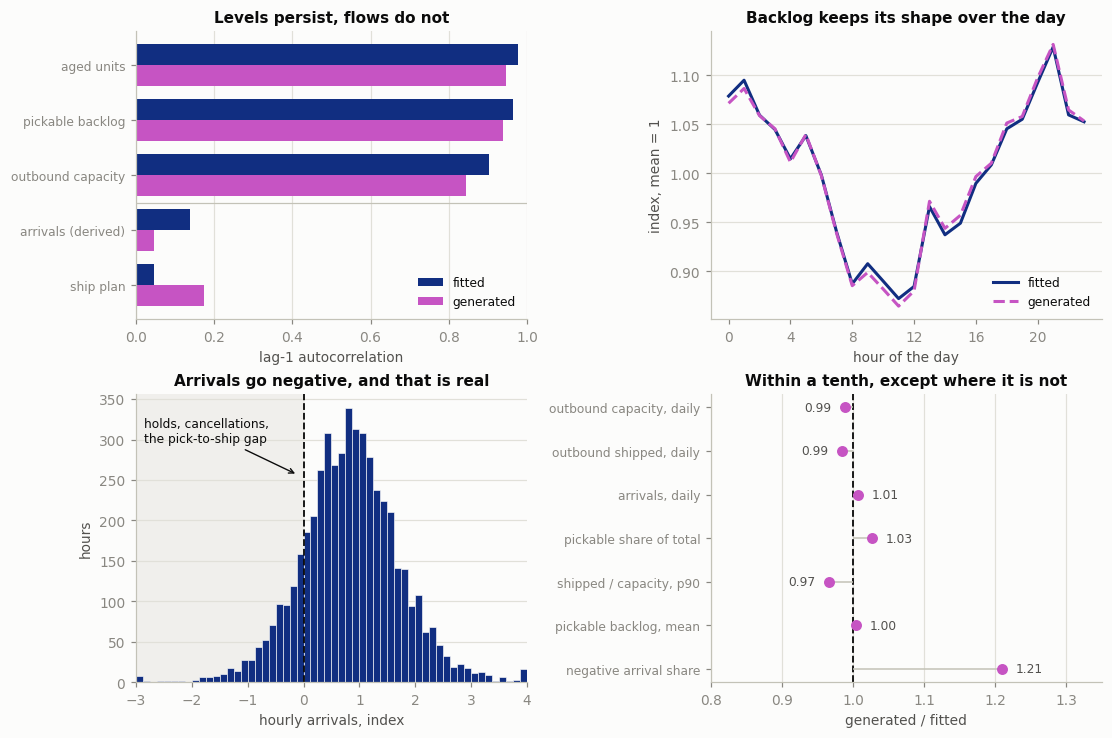

In [50]:
fit = {n: DATA / f"fit_{n}.csv"
       for n in ("persistence", "profiles", "arrivals", "calibration")}
if not all(p.exists() for p in fit.values()):
    print("missing:", [p.name for p in fit.values() if not p.exists()])
else:
    fr = {n: pd.read_csv(p) for n, p in fit.items()}
    fig, axes = plt.subplots(2, 2, figsize=charts.SIZE_FIT, layout="constrained")
    charts.fit_diagnostics(fr["persistence"], fr["profiles"], fr["arrivals"],
                           fr["calibration"], axes.ravel())
    display(fr["persistence"], fr["calibration"])

Generated persistence comes out low because the hour profile is estimated from the same
window and absorbs some of it. What has to survive is the *separation* - every level above
0.84, both flows below 0.18 - not the coefficients.

The negative-arrival share misses by 21%, and its seed-to-seed sd is 0.33 against a miss of
0.21, so closing it would be tuning to noise. `distributions.md` Ã‚Â§0.3 carries a correction:
the free-run drain it used to claim does not reproduce.

### Does the published data satisfy the model's own arithmetic

In [51]:
# CSVs are rounded to one decimal, so each identity combines three values carrying up to
# 0.05 each. The exact 0.000000000 replay identity needs unrounded model output, which these files do not carry.
TOL = 3 * 0.05


def arithmetic(side):
    recursion = throughput = 0.0
    for _, g in detail.groupby("scenario"):
        g = g.sort_values("hour")
        U = g[f"ob_backlog_{side}_units"].to_numpy()
        A = g["ob_arrivals_units"].to_numpy()
        Y = g[f"ob_throughput_{side}_units"].to_numpy()
        C = g[f"ob_capacity_{side}_units"].to_numpy()
        V = np.maximum(U + A, 0.0)
        recursion = max(recursion, np.abs(U[1:] - (V[:-1] - Y[:-1])).max())
        throughput = max(throughput, np.abs(Y - np.minimum(C, V)).max())
    return {"U[h+1] == V[h] - Y[h]": recursion, "Y == min(capacity, V)": throughput}


for side in ("actual", "optimal"):
    for name, err in arithmetic(side).items():
        print(f"{'planned' if side == 'actual' else 'recommended':<12} {name:<24} "
              f"{err:.3f}  {'ok' if err <= TOL else 'FAIL'}")

lin = max((detail[f"ob_capacity_{s}_units"]
           - detail["ob_tph"] * detail[f"ob_people_{s}"]).abs().max()
          for s in ("actual", "optimal"))
print(f"{'both':<12} {'capacity == TPH x people':<24} {lin:.3f}  "
      f"{'ok' if lin <= TOL else 'FAIL'}")

planned      U[h+1] == V[h] - Y[h]    0.100  ok
planned      Y == min(capacity, V)    0.000  ok
recommended  U[h+1] == V[h] - Y[h]    0.100  ok
recommended  Y == min(capacity, V)    0.000  ok
both         capacity == TPH x people 0.050  ok


### Headline figures, recomputed

Each expected value below was copied from the results. A `FAIL` means the data has moved since, so either update the expected value or find out why.

In [52]:
def pct(x): return f"{x:.0%}"
def pct1(x): return f"{x:.1%}"
def num(x): return f"{x:,.0f}"
def hrs(x): return f"{x:.2f}"

x_ib, x_ct, x_ie, x_65 = det("ib_surge"), det("cpt_at_risk"), det("ib_then_eod"), det(case(DAY))
c_ct = x_ct.dropna(subset=["cpt_index"]).set_index("cpt_clock")
c_65 = x_65.dropna(subset=["cpt_index"])
e_ie = x_ie[x_ie["hour"] == cfg.EOD_HOUR].iloc[0]
e_65 = x_65[x_65["hour"] == cfg.EOD_HOUR].iloc[0]
g_bl = risk_carried("baseline")
last_65 = x_65.dropna(subset=["ob_bl_optimal_hours"]).iloc[-1]
mc, pe = breaches("machine_capped").iloc[0], breaches("pool_exhausted").iloc[0]

CHECKS = [
    ("baseline",    "movements",                25,     rev("baseline")["moves_total"].iloc[0], num),
    ("baseline",    "risk reduction",           0.88,   1 - g_bl["after"] / g_bl["before"], pct),
    ("ib_surge",    "hours over the ceiling",   14,     (x_ib["ib_storage_actual_pct"] > 1).sum(), num),
    ("ib_surge",    "planned peak",             1.084,  x_ib["ib_storage_actual_pct"].max(), pct1),
    ("ib_surge",    "recommended peak",         0.898,  x_ib["ib_storage_optimal_pct"].max(), pct1),
    ("cpt",         "15:00 planned",            1.092,  c_ct.loc["15:00", "cpt_risk_actual_pct"], pct1),
    ("cpt",         "15:00 recommended",        1.000,  c_ct.loc["15:00", "cpt_risk_optimal_pct"], pct1),
    ("cpt",         "19:00 planned",            1.033,  c_ct.loc["19:00", "cpt_risk_actual_pct"], pct1),
    ("cpt",         "19:00 recommended",        0.994,  c_ct.loc["19:00", "cpt_risk_optimal_pct"], pct1),
    ("cpt",         "movements",                35,     rev("cpt_at_risk")["moves_total"].iloc[0], num),
    ("three",       "shared breach",            22662,  SHARED, num),
    ("three",       "machine recovered",        0.44,   1 - mc["slack_optimal"] / mc["slack_actual"], pct),
    ("three",       "machine movements",        4,      rev("machine_capped")["moves_total"].iloc[0], num),
    ("three",       "pool recovered",           0.83,   1 - pe["slack_optimal"] / pe["slack_actual"], pct),
    ("three",       "pool movements",           12,     rev("pool_exhausted")["moves_total"].iloc[0], num),
    ("ib_then_eod", "storage planned peak",     1.064,  x_ie["ib_storage_actual_pct"].max(), pct1),
    ("ib_then_eod", "storage recommended peak", 0.908,  x_ie["ib_storage_optimal_pct"].max(), pct1),
    ("ib_then_eod", "eod planned",              4.36,   e_ie["ob_total_actual_units"] / e_ie["eod_capacity_per_hour"], hrs),
    ("ib_then_eod", "eod recommended",          3.40,   e_ie["ob_total_optimal_units"] / e_ie["eod_capacity_per_hour"], hrs),
    ("ib_then_eod", "movements",                83,     rev("ib_then_eod")["moves_total"].iloc[0], num),
    ("fitted",      "days scanned",             200,    fitted_spread["days_scanned"].iloc[0], num),
    ("fitted",      "days breaking one",        2,      fitted_spread.query("families_breached == 1")["days"].iloc[0], num),
    ("fitted",      "days breaking two",        92,     fitted_spread.query("families_breached == 2")["days"].iloc[0], num),
    ("fitted",      "days breaking three",      90,     fitted_spread.query("families_breached == 3")["days"].iloc[0], num),
    ("fitted",      "days breaking four",       16,     fitted_spread.query("families_breached == 4")["days"].iloc[0], num),
    ("fitted",      "cpt live on",              200,    fitted_pairs.query("family_a == 'cpt'")["days_a"].iloc[0], num),
    ("fitted",      "cpt with high backlog",    165,    fitted_pairs.query("family_a == 'cpt' and family_b == 'ob_bl_max'")["days_both"].iloc[0], num),
    ("seed 90065",  "arrivals",                 285722, x_65["ob_arrivals_units"].sum(), num),
    ("seed 90065",  "planned capacity",         236018, x_65["ob_capacity_actual_units"].sum(), num),
    ("seed 90065",  "excess work",              0.21,   x_65["ob_arrivals_units"].sum() / x_65["ob_capacity_actual_units"].sum() - 1, pct),
    ("seed 90065",  "trucks short, planned",    8,      (c_65["cpt_risk_actual_pct"] > 1).sum(), num),
    ("seed 90065",  "worst truck",              1.72,   c_65["cpt_risk_actual_pct"].max(), pct),
    ("seed 90065",  "trucks short, after",      2,      (c_65["cpt_risk_optimal_pct"] > 1).sum(), num),
    ("seed 90065",  "hours below the floor",    8,      len(x_65[x_65["ob_bl_optimal_hours"] < x_65["ob_bl_min_hours"]]), num),
    ("seed 90065",  "final backlog",            5.40,   last_65["ob_bl_optimal_hours"], hrs),
    ("seed 90065",  "band ceiling",             6.00,   last_65["ob_bl_max_hours"], hrs),
    ("seed 90065",  "eod planned",              17.42,  e_65["ob_total_actual_units"] / e_65["eod_capacity_per_hour"], hrs),
    ("seed 90065",  "eod recommended",          14.60,  e_65["ob_total_optimal_units"] / e_65["eod_capacity_per_hour"], hrs),
    ("seed 90065",  "eod limit",                17.09,  e_65["eod_soft_max_hours"], hrs),
    ("seed 90065",  "capacity added",           0.14,   x_65["ob_capacity_optimal_units"].sum() / x_65["ob_capacity_actual_units"].sum() - 1, pct),
    ("seed 90065",  "movements",                87,     rev(case(DAY))["moves_total"].iloc[0], num),
]

# Compared at the precision shown, so 88% is not failed by a computed 0.8805.
out = pd.DataFrame([
    {"section": w, "quantity": q, "expected": f(float(exp)), "data": f(float(got)),
     "match": "ok" if f(float(exp)) == f(float(got)) else "FAIL"}
    for w, q, exp, got, f in CHECKS])

bad = out[out["match"] == "FAIL"]
print(f"{len(out) - len(bad)} of {len(out)} agree")
if len(bad):
    print("\nDRIFT:")
    print(bad.to_string(index=False))
display(out)

41 of 41 agree


,section,quantity,expected,data,match
0,baseline,movements,25,25,ok
1,baseline,risk reduction,88%,88%,ok
2,ib_surge,hours over the ceiling,14,14,ok
3,ib_surge,planned peak,108.4%,108.4%,ok
4,ib_surge,recommended peak,89.8%,89.8%,ok
5,cpt,15:00 planned,109.2%,109.2%,ok
6,cpt,15:00 recommended,100.0%,100.0%,ok
7,cpt,19:00 planned,103.3%,103.3%,ok
8,cpt,19:00 recommended,99.4%,99.4%,ok
9,cpt,movements,35,35,ok
